# Make Global Features

This notebook creates global feature maps for the entire world grid. It processes feature data from the Restrepo dataset and generates global feature arrays that can be used for:

1. **Prediction**: Creating chunked global feature maps (360 chunks) for efficient prediction on the entire globe
2. **Explainability**: Creating a single global feature file (chunk=1) for SHAP and other explainability analyses

The notebook is organized into two main sections, each processing the same features but saving them in different formats optimized for their respective use cases.

In [ ]:
# Import required libraries
import numpy as np
import pandas as pd
import xarray as xr
from os import walk
from pathlib import Path
import sys
import warnings
from multiprocessing import Pool

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Get project root and add to path
project_root = Path().resolve().parents[0] if Path().resolve().name == 'notebooks' else Path().resolve()
if project_root.name != 'mtl-mar':
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from utils import DATA_RAW, DATA_INTERIM

## Part 1: Global Features for Prediction (Chunked)

This section creates global feature maps split into 360 chunks for efficient memory management during prediction. Each chunk is saved as a separate file.

In [ ]:
# Get list of all feature files
restrepo_input_path = DATA_RAW / "features" / "FeaturesPhrampusLee_TOCSedRate_updated"
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_input_path):
    restrepo_files.extend(filenames)
    break

restrepo_files.sort()
print(f"Total feature files found: {len(restrepo_files)}")

510


In [ ]:
# Load selected feature list
# header=None: first line is a feature filename, not a CSV column name
feature_selection = pd.read_csv(DATA_INTERIM / "selectedFeatureLists" / "selectedfeatures_v_men.txt", header=None).values.flatten()
print(f"Selected features: {len(feature_selection)}")

In [ ]:
# Load all selected feature datasets
datasets = []
corrupted_files = 0

for file in restrepo_files:
    if file in feature_selection:
        try:
            rootgrp = xr.open_dataset(restrepo_input_path / file, format='NETCDF4')
            dataset = rootgrp.variables['data']
            datasets.append(dataset)
            
            # Track progress
            if len(datasets) % 10 == 0:
                print(f"Loaded {len(datasets)} feature files...")
        except Exception as e:
            datasets.append(np.nan)
            corrupted_files += 1
            print(f"Warning: Could not load {file}: {e}")

print(f"\nLoaded {len(datasets)} feature datasets")
print(f"Corrupted files: {corrupted_files}")

(array([], dtype=int64), array([], dtype=int64))
DERIVATIVE_lithology_grain_size_Everardo_global_8.nc
File 1 of 510
(array([], dtype=int64), array([], dtype=int64))
EOT20_tidal_ratio_5arcmin_interp_land.nc
File 2 of 510
(array([], dtype=int64), array([], dtype=int64))
EOT20_u3_5arcmin_interp_land.nc
File 3 of 510
(array([], dtype=int64), array([], dtype=int64))
EOT20_umax_5arcmin_interp_land.nc
File 4 of 510
(array([], dtype=int64), array([], dtype=int64))
EOT20_urms_5arcmin_interp_land.nc
File 5 of 510
(array([], dtype=int64), array([], dtype=int64))
GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc
File 6 of 510
(array([], dtype=int64), array([], dtype=int64))
GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc
File 7 of 510
(array([], dtype=int64), array([], dtype=int64))
GL_DIST_TO_COAST_KM_ETOPO.5m.grd
File 8 of 510
(array([], dtype=int64), array([], dtype=int64))
GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd
F

In [ ]:
# Set output path and chunking parameters for prediction
output_path = DATA_INTERIM / "worldfeatures" / "WorldFeaturesAllnoNaN_SedTOC_predict_men"
output_path.mkdir(parents=True, exist_ok=True)

# Chunking parameters: split into 360 chunks for memory efficiency
# Each chunk processes a subset of latitude rows
chunks = 360
lat_step = int(datasets[0].shape[0] / chunks)

print(f"Output path: {output_path}")
print(f"Number of chunks: {chunks}")
print(f"Latitude step per chunk: {lat_step}")
print(f"Dataset shape: {datasets[0].shape}")

In [ ]:
# Function to process a single chunk
def process_chunk(ii):
    """
    Process a single chunk of global features.
    
    Args:
        ii: Chunk index (0 to chunks-1)
    
    Returns:
        None (saves chunk to disk)
    """
    # Initialize feature chunk array
    feature_chunk = np.zeros([lat_step * datasets[0].shape[1], len(datasets)])

    # Extract features for this chunk from all datasets
    for idx in range(len(datasets)):
        if datasets[idx] is not np.nan:
            # Extract latitude slice and flatten
            feature_chunk[:, idx] = np.asarray(
                datasets[idx][ii * lat_step:ii * lat_step + lat_step, :]
            ).flatten(order="C")
        else:
            feature_chunk[:, idx] = np.nan

    # Save chunk to disk
    save_name = "Sed_world_feature_" + str(ii).zfill(3)
    np.save(output_path / save_name, feature_chunk)
    print(f"Chunk {ii + 1} of {chunks} written!")

# Process all chunks using multiprocessing
print(f"Processing {chunks} chunks with multiprocessing...")
pool = Pool(processes=64)  # Adjust number of processes based on available CPUs
pool.map(process_chunk, range(chunks))
pool.close()
pool.join()

print(f"\nAll chunks saved to: {output_path}")

Chunk 75 of 360 written!Chunk 47 of 360 written!Chunk 89 of 360 written!Chunk 105 of 360 written!Chunk 15 of 360 written!Chunk 3 of 360 written!Chunk 97 of 360 written!Chunk 45 of 360 written!Chunk 31 of 360 written!
Chunk 29 of 360 written!








Chunk 39 of 360 written!Chunk 25 of 360 written!

Chunk 11 of 360 written!Chunk 7 of 360 written!
Chunk 33 of 360 written!

Chunk 5 of 360 written!
Chunk 41 of 360 written!
Chunk 57 of 360 written!Chunk 27 of 360 written!

Chunk 23 of 360 written!
Chunk 63 of 360 written!Chunk 43 of 360 written!

Chunk 49 of 360 written!
Chunk 71 of 360 written!Chunk 13 of 360 written!
Chunk 35 of 360 written!

Chunk 69 of 360 written!Chunk 19 of 360 written!

Chunk 103 of 360 written!
Chunk 37 of 360 written!
Chunk 17 of 360 written!
Chunk 67 of 360 written!Chunk 85 of 360 written!

Chunk 95 of 360 written!Chunk 119 of 360 written!
Chunk 61 of 360 written!

Chunk 83 of 360 written!
Chunk 51 of 360 written!
Chunk 79 of 360 written!
Chunk 55 of 360 written!


## Part 2: Global Features for Explainability (Single Chunk)

This section creates a single global feature file (chunk=1) optimized for SHAP and other explainability analyses. The features are masked to exclude land areas.

# Load land mask to exclude land areas from features
land_file = DATA_RAW / "island_map.npy"
if not land_file.exists():
    land_file = DATA_RAW / "labels" / "island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1  # Set NaNs to 1 (land)
land_map = np.rot90(np.rot90(np.fliplr(land_map)))  # Rotate to match feature grid orientation

print(f"Land map shape: {land_map.shape}")
print(f"Land pixels: {np.sum(land_map == 1)}")
print(f"Ocean pixels: {np.sum(land_map == 0)}")

In [ ]:
# Load all selected feature datasets with land masking
datasets_explain = []
corrupted_files_explain = 0

for file in restrepo_files:
    if file in feature_selection:
        try:
            rootgrp = xr.open_dataset(restrepo_input_path / file, format='NETCDF4')
            dataset = rootgrp.variables['data']
            
            # Convert to numpy array and apply land mask
            dataset_array = np.array(dataset)
            dataset_masked = dataset_array.copy()
            dataset_masked[land_map == 1] = np.nan
            
            datasets_explain.append(dataset_masked)
            
            # Track progress
            if len(datasets_explain) % 10 == 0:
                print(f"Loaded {len(datasets_explain)} feature files...")
        except Exception as e:
            datasets_explain.append(np.nan)
            corrupted_files_explain += 1
            print(f"Warning: Could not load {file}: {e}")

print(f"\nLoaded {len(datasets_explain)} feature datasets for explainability")
print(f"Corrupted files: {corrupted_files_explain}")

In [ ]:
# Set output path for explainability features
output_path_explain = DATA_INTERIM / "worldfeatures" / "WorldFeaturesAllnoNaN_SedTOC_explain"
output_path_explain.mkdir(parents=True, exist_ok=True)

print(f"Output path: {output_path_explain}")
if len(datasets_explain) > 0 and not (isinstance(datasets_explain[0], float) and np.isnan(datasets_explain[0])):
    print(f"Dataset shape: {datasets_explain[0].shape}")

510


In [ ]:
# Create single feature array for explainability
if len(datasets_explain) > 0 and not (isinstance(datasets_explain[0], float) and np.isnan(datasets_explain[0])):
    dataset_shape = datasets_explain[0].shape
    feature_chunk_explain = np.zeros([dataset_shape[0] * dataset_shape[1], len(datasets_explain)])

    print(f"Creating feature array: {feature_chunk_explain.shape}")
    print("Flattening features...")

    # Flatten each feature dataset and stack them
    for idx in range(len(datasets_explain)):
        if not (isinstance(datasets_explain[idx], float) and np.isnan(datasets_explain[idx])):
            feature_chunk_explain[:, idx] = np.asarray(datasets_explain[idx]).flatten(order="C")
        else:
            feature_chunk_explain[:, idx] = np.nan
        
        if (idx + 1) % 10 == 0:
            print(f"  Processed {idx + 1}/{len(datasets_explain)} features...")
else:
    print("Error: No valid datasets loaded")

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'gmt' loading failed:
Error loading GMT shared library at 'libgmt.so'.
libgmt.so: cannot open shared object file: No such file or directory
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


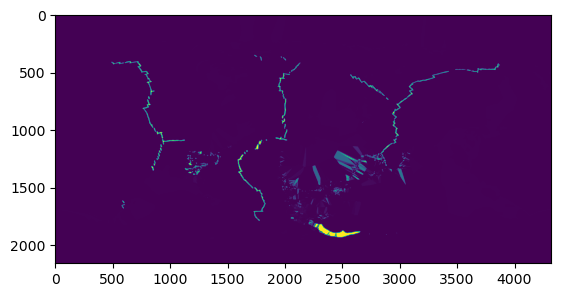

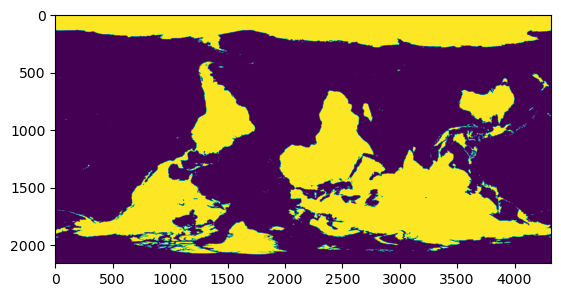

(2160, 4320)
DERIVATIVE_lithology_grain_size_Everardo_global_8.nc
File 1 of 510
(2160, 4320)
EOT20_tidal_ratio_5arcmin_interp_land.nc
File 2 of 510
(2160, 4320)
EOT20_u3_5arcmin_interp_land.nc
File 3 of 510
(2160, 4320)
EOT20_umax_5arcmin_interp_land.nc
File 4 of 510
(2160, 4320)
EOT20_urms_5arcmin_interp_land.nc
File 5 of 510
(2160, 4320)
GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc
File 6 of 510
(2160, 4320)
GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc
File 7 of 510
(2160, 4320)
GL_DIST_TO_COAST_KM_ETOPO.5m.grd
File 8 of 510
(2160, 4320)
GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd
File 9 of 510
(2160, 4320)
GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd
File 10 of 510
(2160, 4320)
GL_ELEVATION_M_ASL_ETOPO2v2.r50km.men.5m.grd
File 11 of 510
(2160, 4320)
GL_HEATFLUX_MWM2_Becker.5m.nc
File 12 of 510
(2160, 4320)
GL_HEATFLUX_MWM2_Becker_r50km_men.nc
File 13 of 510
(2160, 4320)
GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.5m.grd
F

In [ ]:
# Save single file for explainability
save_name = "Sed_world_feature_000"
if 'feature_chunk_explain' not in globals():
    raise RuntimeError('feature_chunk_explain was not built; check Part 2 dataset loading above.')
np.save(output_path_explain / save_name, feature_chunk_explain)

print(f"\nWorld features saved to single file: {output_path_explain / save_name}")
print(f"Feature array shape: {feature_chunk_explain.shape}")
print("Ready for explainability analysis (SHAP, etc.)!")

In [ ]:
# Verify saved file
print("\nVerification:")
print(f"  - Saved file: {output_path_explain / save_name}")
print(f"  - Feature array shape: {feature_chunk_explain.shape}")
print(f"  - Number of pixels: {feature_chunk_explain.shape[0]}")
print(f"  - Number of features: {feature_chunk_explain.shape[1]}")
print(f"  - Memory size: {feature_chunk_explain.nbytes / 1e9:.2f} GB")